In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Data directory
base_path = "/Users/gracie/Desktop/DATA/DATA 300/Project"

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (



### DATA CLEANING ###

In [2]:
# Load all data
dfs = []

# Loop through years and months
for year in range(2020, 2026):  # 2020–2025
    for month in range(1, 13):  # Jan–Dec
        
        file_path = f"{base_path}/{year}/T_ONTIME_REPORTING-{month}.csv"
        
        if os.path.exists(file_path):  # safety check
            df_temp = pd.read_csv(file_path)
            
            # Add year + month explicitly
            df_temp["YEAR"] = year
            df_temp["MONTH"] = month
            
            dfs.append(df_temp)
        else:
            print(f"Missing file: {file_path}")

# Combine everything into one dataframe
df = pd.concat(dfs, ignore_index=True)

/var/folders/91/4d0_7f2176gdgm2kh89mg4s40000gn/T/ipykernel_64041/4119370907.py:11: DtypeWarning: Columns (0: CANCELLATION_CODE) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(file_path)
/var/folders/91/4d0_7f2176gdgm2kh89mg4s40000gn/T/ipykernel_64041/4119370907.py:11: DtypeWarning: Columns (0: CANCELLATION_CODE) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(file_path)
/var/folders/91/4d0_7f2176gdgm2kh89mg4s40000gn/T/ipykernel_64041/4119370907.py:11: DtypeWarning: Columns (0: CANCELLATION_CODE) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(file_path)
/var/folders/91/4d0_7f2176gdgm2kh89mg4s40000gn/T/ipykernel_64041/4119370907.py:11: DtypeWarning: Columns (0: CANCELLATION_CODE) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(file_path)
/var/folders/91/4d0_7f2176gdgm2kh89mg4s40000gn/T/ipy

In [ ]:
# 2. Cleaning

# Keep only MDT flights
df = df[df["ORIGIN"] == "MDT"]

# Remove cancelled flights
df = df[df["CANCELLED"] == 0]

# Drop missing target
df = df.dropna(subset=["ARR_DEL15"])

# Keep only needed columns
df = df[[
    "YEAR",
    "MONTH",
    "DAY_OF_MONTH",
    "DAY_OF_WEEK",
    "CRS_DEP_TIME",
    "OP_UNIQUE_CARRIER",
    "DEST",
    "DISTANCE",
    "CRS_ELAPSED_TIME",
    "TAIL_NUM",
    "FL_DATE",
    "ARR_DEL15",
    "ARR_DELAY_NEW"
]]

# Convert types
df["ARR_DEL15"] = df["ARR_DEL15"].astype(int)
df["ARR_DELAY_NEW"] = df["ARR_DELAY_NEW"].astype(int)
df["DISTANCE"] = pd.to_numeric(df["DISTANCE"], errors="coerce")
df["CRS_DEP_TIME"] = pd.to_numeric(df["CRS_DEP_TIME"], errors="coerce")
df["CRS_ELAPSED_TIME"] = pd.to_numeric(df["CRS_ELAPSED_TIME"], errors="coerce")

# Drop any remaining missing values
df = df.dropna()

# Create usable time feature (replaces raw CRS_DEP_TIME)
df["DEP_HOUR"] = df["CRS_DEP_TIME"] // 100


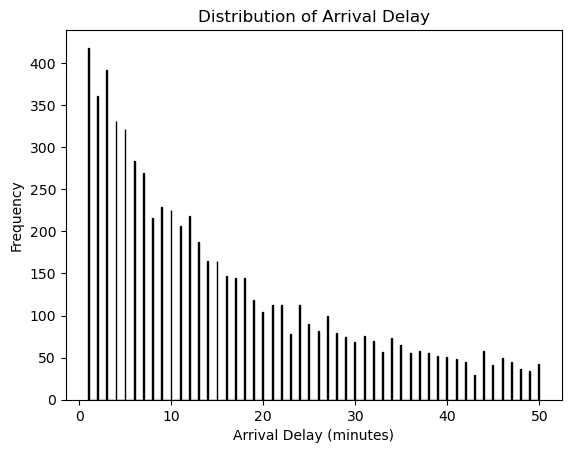

In [11]:
import matplotlib.pyplot as plt

plt.hist(df["ARR_DELAY_NEW"], bins=500, range=(1, 50), color="blue", edgecolor="black")
plt.title("Distribution of Arrival Delay")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Frequency")
plt.show()

In [4]:
df['FL_DATE'] = pd.to_datetime(df['FL_DATE'], format='%m/%d/%Y %I:%M:%S %p')
# Ensure data is ordered so 'previous' actually means 'earlier that day'
df = df.sort_values(['TAIL_NUM', 'FL_DATE', 'CRS_DEP_TIME'], ascending=[True, True, True])

# Identify if the plane was late on its previous leg
# We use 'ARR_DEL15' from the previous row (shift)
df['PREV_FLIGHT_DELAYED'] = df.groupby(['TAIL_NUM', 'FL_DATE'])['ARR_DEL15'].shift(1)

# Fill NaN (the first flight of the day for a plane has no "previous" flight)
df['PREV_FLIGHT_DELAYED'] = df['PREV_FLIGHT_DELAYED'].fillna(0)

df['PREV_FLIGHT_DELAYED'] = df['PREV_FLIGHT_DELAYED'].astype(int)

In [5]:
df.to_csv(f"{base_path}/cleaned_flight_data.csv", index=False)

### EXPLORATORY DATA ANALYSIS ###

In [6]:
# Data overview
df.shape
df.info()

<class 'pandas.DataFrame'>
Index: 29281 entries, 1087201 to 809569
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   YEAR                 29281 non-null  int64         
 1   MONTH                29281 non-null  int64         
 2   DAY_OF_MONTH         29281 non-null  int64         
 3   DAY_OF_WEEK          29281 non-null  int64         
 4   CRS_DEP_TIME         29281 non-null  int64         
 5   OP_UNIQUE_CARRIER    29281 non-null  str           
 6   DEST                 29281 non-null  str           
 7   DISTANCE             29281 non-null  float64       
 8   CRS_ELAPSED_TIME     29281 non-null  float64       
 9   TAIL_NUM             29281 non-null  str           
 10  FL_DATE              29281 non-null  datetime64[us]
 11  ARR_DEL15            29281 non-null  int64         
 12  DEP_HOUR             29281 non-null  int64         
 13  PREV_FLIGHT_DELAYED  29281 non-null  int

In [57]:
df.head()

,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,CRS_DEP_TIME,OP_UNIQUE_CARRIER,DEST,DISTANCE,CRS_ELAPSED_TIME,TAIL_NUM,FL_DATE,ARR_DEL15,DEP_HOUR,PREV_FLIGHT_DELAYED
1087201,2024,2,19,1,1957,G4,FLL,993.0,177.0,188NV,2024-02-19,1,19,0
1145294,2024,5,2,4,1536,G4,MYR,465.0,86.0,188NV,2024-05-02,0,15,0
1145295,2024,5,2,4,2017,G4,SFB,827.0,138.0,188NV,2024-05-02,0,20,0
1146148,2024,5,3,5,1642,G4,SFB,827.0,138.0,188NV,2024-05-03,0,16,0
1147800,2024,5,5,7,1536,G4,MYR,465.0,86.0,188NV,2024-05-05,0,15,0


In [7]:
# Summary statistics
df.describe()

,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,CRS_DEP_TIME,DISTANCE,CRS_ELAPSED_TIME,FL_DATE,ARR_DEL15,DEP_HOUR,PREV_FLIGHT_DELAYED
count,29281.000000,29281.000000,29281.000000,29281.000000,29281.000000,29281.000000,29281.000000,29281,29281.000000,29281.000000,29281.000000
mean,2022.645060,6.660394,15.735289,4.043031,1202.140193,611.599672,126.417609,2023-02-26 19:53:30.996892,0.173935,11.771763,0.004508
min,2020.000000,1.000000,1.000000,1.000000,500.000000,84.000000,47.000000,2020-01-01 00:00:00,0.000000,5.000000,0.000000
25%,2021.000000,4.000000,8.000000,2.000000,650.000000,413.000000,102.000000,2021-10-10 00:00:00,0.000000,6.000000,0.000000
50%,2023.000000,7.000000,16.000000,4.000000,1213.000000,594.000000,124.000000,2023-03-27 00:00:00,0.000000,12.000000,0.000000
75%,2024.000000,10.000000,23.000000,6.000000,1707.000000,620.000000,138.000000,2024-07-26 00:00:00,0.000000,17.000000,0.000000
max,2025.000000,12.000000,31.000000,7.000000,2250.000000,2369.000000,358.000000,2025-12-31 00:00:00,1.000000,22.000000,1.000000
std,1.640756,3.400272,8.746727,2.016105,488.809464,251.066385,32.767897,NaN,0.379060,4.839916,0.066992


In [8]:
# Class balance
df["ARR_DEL15"].value_counts()
df["ARR_DEL15"].value_counts(normalize=True)

ARR_DEL15
0    0.826065
1    0.173935
Name: proportion, dtype: float64

In [20]:
# Airline distribution
df["OP_UNIQUE_CARRIER"].value_counts()

OP_UNIQUE_CARRIER
G4    4843
OH    4000
AA    3988
OO    3800
DL    3708
9E    3184
MQ    1987
UA    1557
YX    1520
F9     687
YV       7
Name: count, dtype: int64

In [10]:
# Destination distribution
df["DEST"].value_counts()

DEST
CLT    6303
ORD    5601
ATL    5349
DTW    3713
DFW    2017
SFB    1563
PIE     825
PGD     758
EWR     660
MCO     632
SRQ     557
BNA     459
MYR     299
FLL     243
JAX     139
PHL      84
DEN      55
MIA      11
IAD       7
MSP       2
EUG       1
SEA       1
PHX       1
LAX       1
Name: count, dtype: int64

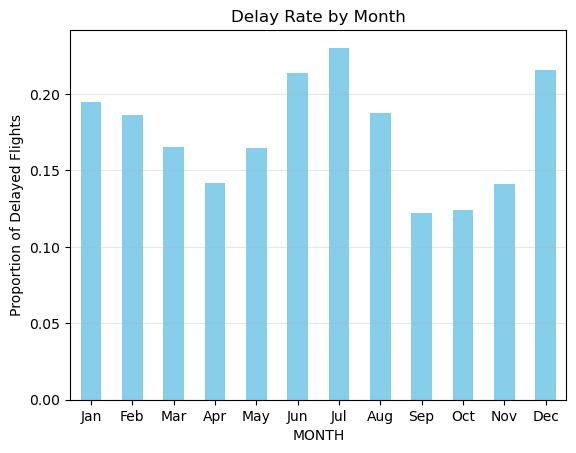

In [50]:
monthly = df.groupby("MONTH")["ARR_DEL15"].mean()

monthly.plot(kind="bar", color="skyblue")

plt.title("Delay Rate by Month")
plt.ylabel("Proportion of Delayed Flights")
plt.xticks(ticks=range(12), labels=[
    "Jan","Feb","Mar","Apr","May","Jun",
    "Jul","Aug","Sep","Oct","Nov","Dec"
])
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

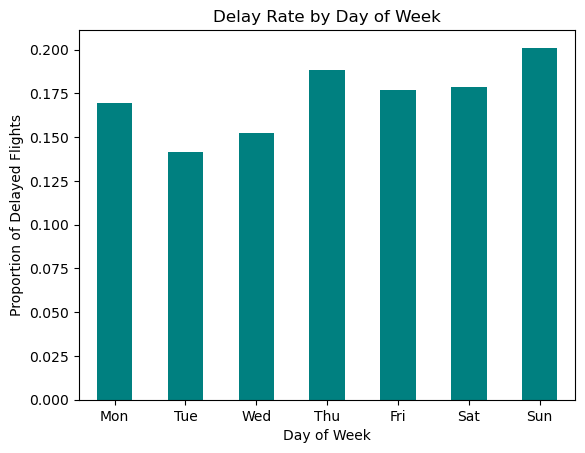

In [59]:
# Delays by day of week
df.groupby("DAY_OF_WEEK")["ARR_DEL15"].mean().plot(kind="bar", color="teal")
plt.title("Delay Rate by Day of Week")
plt.xticks(ticks=range(7), labels=[
    "Mon","Tue","Wed","Thu","Fri","Sat","Sun"
])
plt.xticks(rotation=0)
plt.xlabel("Day of Week")
plt.ylabel("Proportion of Delayed Flights")

plt.show()

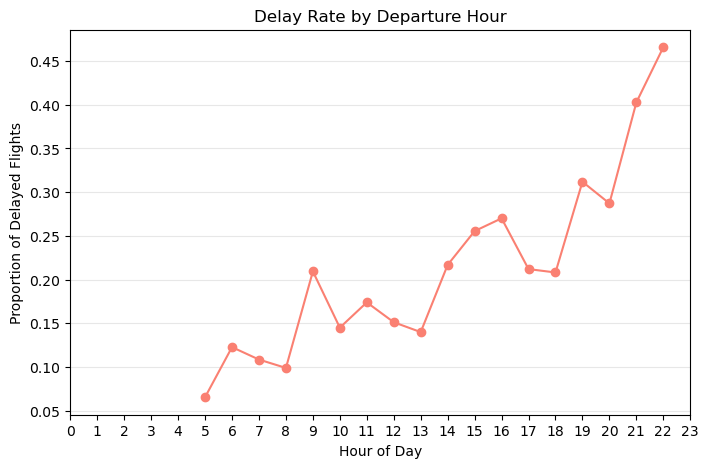

In [58]:
# Delays by departure hour
hourly_delay = df.groupby("DEP_HOUR")["ARR_DEL15"].mean()

plt.figure(figsize=(8,5))
plt.plot(hourly_delay.index, hourly_delay.values, marker='o', color='salmon')

plt.title("Delay Rate by Departure Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Proportion of Delayed Flights")

plt.xticks(range(0, 24))  # clean x-axis
plt.grid(axis='y', alpha=0.3)

plt.show()

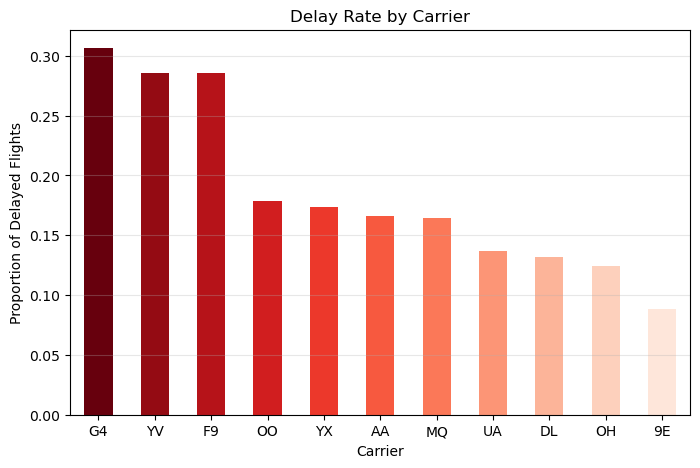

In [55]:
# Delays by carrier
carrier_col = "OP_UNIQUE_CARRIER"

carrier_delay = (
    df.groupby(carrier_col)["ARR_DEL15"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))
carrier_delay.plot(kind="bar", color=cm.Reds(carrier_delay.rank(pct=True)))
plt.title("Delay Rate by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Proportion of Delayed Flights")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

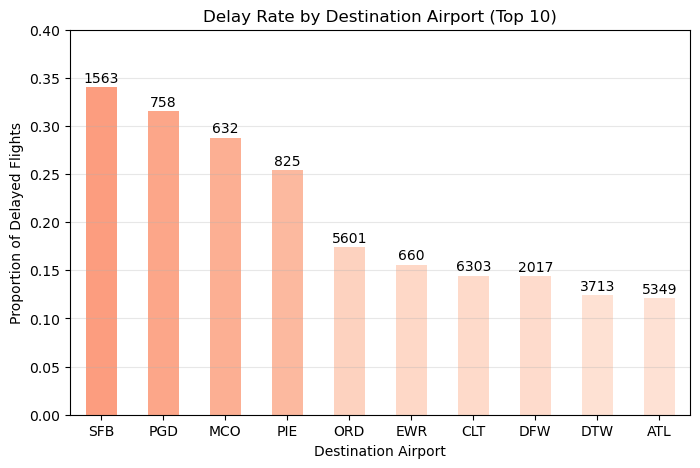

In [56]:
top_dest = df["DEST"].value_counts().head(10).index

dest_delay = (
    df[df["DEST"].isin(top_dest)]
    .groupby("DEST")["ARR_DEL15"]
    .mean()
    .sort_values(ascending=False)
)

counts = df[df["DEST"].isin(top_dest)]["DEST"].value_counts()
counts = counts[dest_delay.index]

import matplotlib.cm as cm

colors = cm.Reds(dest_delay.values)

ax = dest_delay.plot(kind="bar", figsize=(8,5), color=colors)
for i, v in enumerate(dest_delay.index):
    ax.text(i, dest_delay[v] + 0.005, str(counts[v]), ha='center')

plt.title("Delay Rate by Destination Airport (Top 10)")
plt.xlabel("Destination Airport")
plt.ylabel("Proportion of Delayed Flights")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.ylim(0, 0.4)

plt.show()

In [21]:
pd.crosstab(df['PREV_FLIGHT_DELAYED'], df['ARR_DEL15'], normalize='index')

ARR_DEL15,0,1
PREV_FLIGHT_DELAYED,,
0,0.828433,0.171567
1,0.303030,0.696970


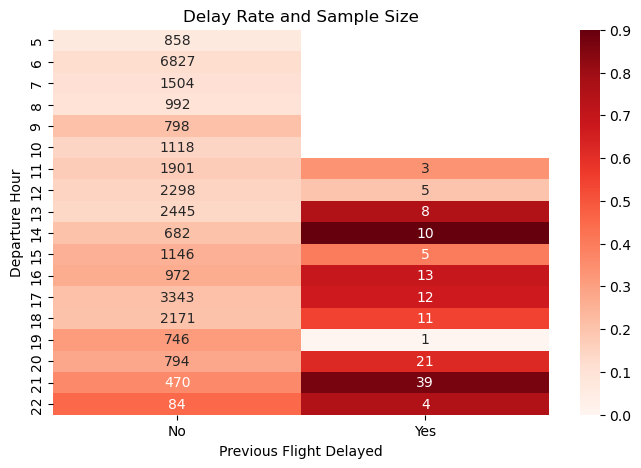

In [ ]:
counts = df.groupby(['DEP_HOUR', 'PREV_FLIGHT_DELAYED']).size().unstack()
rates = df.groupby(['DEP_HOUR', 'PREV_FLIGHT_DELAYED'])['ARR_DEL15'].mean().unstack()
rates.columns = ['No', 'Yes']
counts.columns = ['No', 'Yes']

plt.figure(figsize=(8,5))
sns.heatmap(rates, annot=counts, fmt=".0f", cmap="Reds")
plt.title("Delay Rate and Sample Size")
plt.xlabel("Previous Flight Delayed")
plt.ylabel("Departure Hour")

plt.show()

### SPLITTING DATA ###

In [16]:
X = df[[
    "MONTH",
    "DAY_OF_MONTH",
    "DAY_OF_WEEK",
    "CRS_DEP_TIME",
    "OP_UNIQUE_CARRIER",
    "DEST",
    "DISTANCE",
    "CRS_ELAPSED_TIME",
    "PREV_FLIGHT_DELAYED",
    "DEP_HOUR"
]]

y = df["ARR_DEL15"]

In [17]:
X = pd.get_dummies(
    X,
    columns=["OP_UNIQUE_CARRIER", "DEST"],
    drop_first=True
)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTrain class balance:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest class balance:")
print(y_test.value_counts(normalize=True).round(3))

Train shape: (23424, 41)
Test shape: (5857, 41)

Train class balance:
ARR_DEL15
0    0.826
1    0.174
Name: proportion, dtype: float64

Test class balance:
ARR_DEL15
0    0.826
1    0.174
Name: proportion, dtype: float64
